# Residual correlation and the $\sigma_m$ to use in the inversion

The likelihood treats every picked frequency of a dispersion curve as an independent observation,

$$\hat k_{s,m}(f_j) \sim \mathcal N\big(k_m(f_j;\theta),\ \sigma_m^2\big).$$

However, neighbouring frequencies of one FK ridge are not independent (spectral leakage, finite frequency resolution, etc...), so the $n$ samples of a mode carry the information of fewer, $n_\mathrm{eff}$, independent ones. From the residuals of a preliminary fit this notebook first removes outlier picks, then measures, per mode $m$ among QS, QS0 and SH0:

- outlier picks: residuals more than 5 robust standard deviations from the mode's median residual. They are removed, the cleaned events are saved for `step3_invert_fixed.ipynb`, and the fit is repeated without them;
- the variance inflation factor $\mathrm{VIF} = 1 + 2\sum_L (1 - L/n)\,\rho_L$, from the within-curve residual autocorrelation $\rho_L$ at frequency lag $L$, and $n_\mathrm{eff} = n/\mathrm{VIF}$;
- the residual scatter $\sigma_\mathrm{rms}$ (rad/m) is the root-mean-square residual of each mode at the preliminary MAP, i.e. the empirical standard deviation of the picks about the model
- the $\sigma_m$ to use in the inversion, $\sigma_\mathrm{adjusted} = \sigma_\mathrm{rms}\sqrt{\mathrm{VIF}}$, which weights each curve as the $n_\mathrm{eff}$ samples it is worth rather than $n$.

**Inputs**: the events from `step1_preprocess.ipynb`, in `outputs/tap_inv_batch/`. **Outputs**: the cleaned events (`dispersion_events_0908_clean.npz`) and the `SIGMA_BY_WAVE` that `step3_invert_fixed.ipynb` uses; the figure goes to `outputs/tap_inv_batch/residuals/`.

The outlier picking is based on Leys, C., Ley, C., Klein, O., Bernard, P., & Licata, L. (2013). Detecting outliers: Do not use standard deviation around the mean, use absolute deviation around the median. Journal of Experimental Social
Psychology, 49(4), 764-766. doi:10.1016/j.jesp.2013.03.013

The VIF definition is by multiplying both sides of Eq. (14) of Bayley, G. V., & Hammersley, J. M. (1946). The "effective" number of independent observations in an autocorrelated time series. Supplement to the Journal of the Royal Statistical Society, 8(2), 184–197.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from das_tools.hammer_inversion import (
    ParameterGrid, invert_cached, load_events,
    get_fg_cache, plot_sigma_and_gaussian, set_wave_sigmas,
    standardized_residuals, residual_acf, drop_outlier_picks, save_events,
)
from das_tools.utils import proj_path

# Inputs and outputs live under outputs/tap_inv_batch/ in the project
# (das_tools.utils.proj_path; DAS_LFI_OUTPUT_DIR moves it).
OUT = proj_path.output_dir("tap_inv_batch")
EVENTS_FILE = OUT / "dispersion_events_0908.npz"
CACHE_FILE = OUT / "dispersion_cache_wavegrids_detailed.npz"
CLEAN_EVENTS_FILE = OUT / "dispersion_events_0908_clean.npz"   # read by step3_invert_fixed.ipynb
FIG_SUP =  proj_path.figures_dir("supplementary")
FIG_DIR = FIG_SUP / "S4_hammer_inv_residual"

SIGMA = 0.10         # constant sigma_m [rad/m] used for the preliminary fit
N_SIGMA_OUTLIER = 5.0   # outlier threshold, in robust standard deviations (1.4826 MAD)
SAVE_FIGS = True

# --- must match step3_invert_fixed.ipynb -----------------------------------
MODEL_CONSTANTS = dict(h_w=10.0, rho_i=910.0, rho_w=1025.0, P=0.0)
BOUNDS = [(0.5e9, 10.0e9), (0.05, 0.45), (0.75, 1.25)]
GRID_SIZE = dict(n_E=181, n_nu=81, n_h_i=101)
FG_FREQUENCY = np.arange(5.0, 50.0 + 0.5, 1.0)

## 1. Preliminary fit

Every event with a constant $\sigma_m$ = `SIGMA`, on the same grid and forward-model cache as `step3_invert_fixed.ipynb`.

In [2]:
grid = ParameterGrid.from_bounds(*BOUNDS, **GRID_SIZE)
events_raw = load_events(EVENTS_FILE)
events = set_wave_sigmas(events_raw, {wt: SIGMA for wt in ("P", "SH", "FG")})

# The same cache as step3_invert_fixed.ipynb; rebuilt (~50 s) only if it is missing,
# out of date, or was built for other settings.
cache = get_fg_cache(CACHE_FILE, grid, MODEL_CONSTANTS, FG_FREQUENCY)

_, result = invert_cached(events, grid, cache, per_event=False)
print("Preliminary global MAP:", {k: f"{v:.4g}" for k, v in result.map_params.items()})

Loaded 23 events from:
/Users/junsuj/Desktop/git/das-landfast-ice-inversion2025/outputs/tap_inv_batch/dispersion_events_0908.npz
Preliminary global MAP: {'E': '5.408e+09', 'nu': '0.215', 'h_i': '0.95'}


## 2. Outlier picks

For each mode, picks whose residual lies more than `N_SIGMA_OUTLIER` robust standard deviations ($\hat\sigma = 1.4826\,\mathrm{MAD}$, which the outliers themselves do not inflate) from the mode's median residual are removed. The cleaned events are saved for `step3_invert_fixed.ipynb`, and the fit is repeated without them, since the outliers also pulled on the first fit.

In [3]:
rows = standardized_residuals(events, cache=cache, result=result)
events, outlier_report = drop_outlier_picks(events, rows, n_sigma=N_SIGMA_OUTLIER)
display(pd.DataFrame(outlier_report))
save_events(events, CLEAN_EVENTS_FILE)

_, result = invert_cached(events, grid, cache, per_event=False)
print("Global MAP without outliers:", {k: f"{v:.4g}" for k, v in result.map_params.items()})

,wave,n,n_removed,median,robust_std,threshold
0,FG,1360,51,-0.014025,0.013789,0.068944
1,P,439,12,-0.000601,0.010582,0.052910
2,SH,51,0,-0.002326,0.035600,0.178000


Saved 23 events to:
/Users/junsuj/Desktop/git/das-landfast-ice-inversion2025/outputs/tap_inv_batch/dispersion_events_0908_clean.npz
Global MAP without outliers: {'E': '5.408e+09', 'nu': '0.225', 'h_i': '0.98'}


## 3. VIF, effective sample size and $\sigma_m$

From the residuals $\hat k - k_\mathrm{pred}$ at the MAP of the fit without outliers, per mode: the VIF (from the within-curve residual autocorrelation), $\sigma_\mathrm{rms}$ (the root-mean-square residual, rad/m) and $\sigma_\mathrm{adjusted} = \sigma_\mathrm{rms}\sqrt{\mathrm{VIF}}$. The last line is the `SIGMA_BY_WAVE` to use in `step3_invert_fixed.ipynb`.

In [4]:
rows = standardized_residuals(events, cache=cache, result=result)
acf = residual_acf(rows)

SIGMA_BY_WAVE = {}
for wt, d in pd.DataFrame(rows).groupby("wave"):
    vif = acf[wt]["vif"]
    sigma_rms = float(np.sqrt(np.mean(d["residual"] ** 2)))     # rad/m
    sigma_adjusted = sigma_rms * float(np.sqrt(vif))
    SIGMA_BY_WAVE[wt] = round(sigma_adjusted, 4)
    print(f"{wt}: VIF = {vif:.2f}, sigma_rms = {sigma_rms:.4f}, sigma_adjusted = {sigma_adjusted:.4f} rad/m")

print("\nSIGMA_BY_WAVE =", SIGMA_BY_WAVE)

FG: VIF = 7.84, sigma_rms = 0.0168, sigma_adjusted = 0.0471 rad/m
P: VIF = 2.83, sigma_rms = 0.0124, sigma_adjusted = 0.0209 rad/m
SH: VIF = 4.68, sigma_rms = 0.0292, sigma_adjusted = 0.0631 rad/m

SIGMA_BY_WAVE = {'FG': 0.0471, 'P': 0.0209, 'SH': 0.0631}


QS Gaussian fit: $\mu$=-0.0012, $\hat{\sigma}$=0.0168 rad/m
QS0 Gaussian fit: $\mu$=-0.0001, $\hat{\sigma}$=0.0124 rad/m
SH0 Gaussian fit: $\mu$=-0.0046, $\hat{\sigma}$=0.0291 rad/m


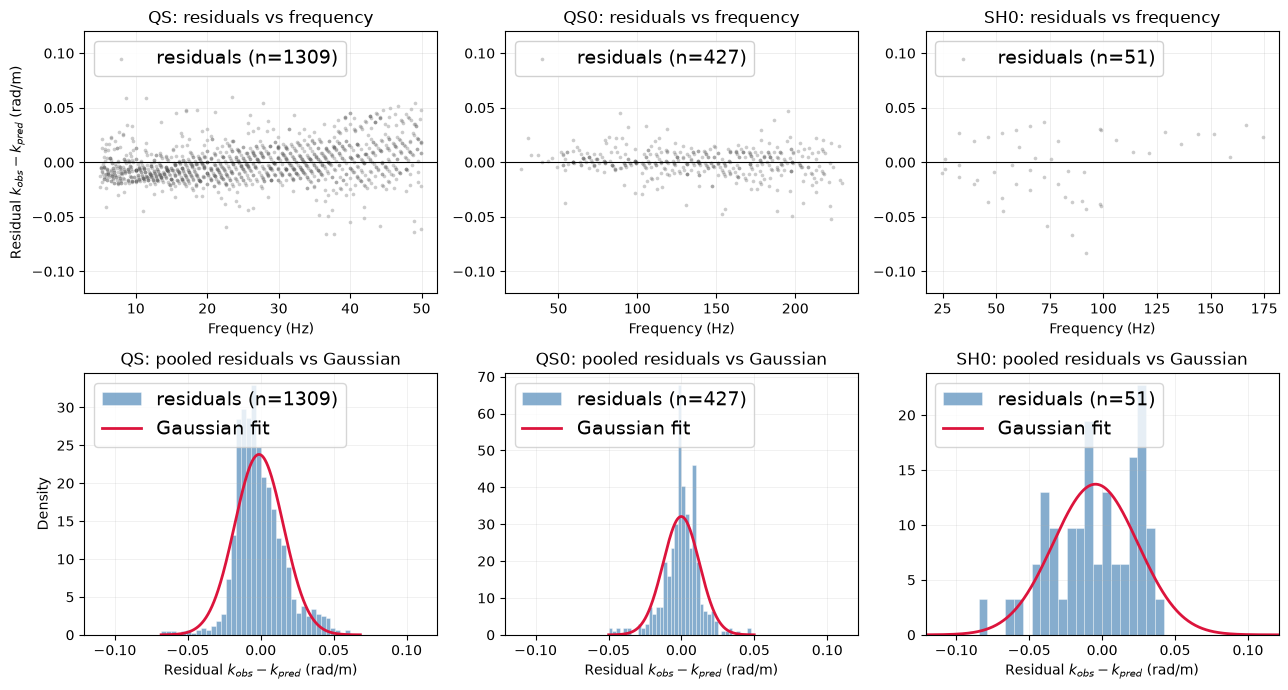

In [5]:
fig = plot_sigma_and_gaussian(rows)
if SAVE_FIGS:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG_DIR / "residuals_sigma_gaussian.pdf",
        format="pdf",
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.2,)
plt.show()